# Task 2: Classical Authentication (Person B)
**Question:** a user claims an identity and types `.tie5Roanl`. Is it really them, or an impostor?

Unlike Task 1, there is no 51-way classifier here. Each user gets their **own detector**, trained only on their **own** typing (one-class / anomaly detection). The detector outputs a score, and a threshold on that score accepts or rejects. We report the **Equal Error Rate (EER)**: the threshold where the false-accept rate equals the false-reject rate. Lower is better.

**Protocol (Killourhy & Maxion, DSN-2009), frozen in `split.txt`.** For each of the 51 users:
- **train:** their 200 reps from sessions 1-4
- **genuine test:** their 200 reps from sessions 5-8
- **impostor test:** the first 5 reps of each of the other 50 users, from `IMPOSTOR_SESSION` (= session 1, as in the paper): 250 impostor attempts

Report the mean (and std) of the 51 per-user EERs, and compare with the paper's published table.

**Rules followed:** the detector never sees impostor data while training. Hyperparameters are chosen on a **validation protocol inside sessions 1-4** (train on 1-3, genuine = session 4, impostors = session 2), never on the test sessions. Score convention: higher = more likely genuine (`metrics.py`).

Sections: 0 Setup · 1 Data and protocol · 2 Detectors · 3 Hyperparameters (validation only) · 4 Main results vs the paper · 5 ROC curves and error trade-offs · 6 Practiced impostors · 7 Drift across test sessions · 8 Ablations (features, training size) · 9 Per-user difficulty · 10 Summary and saved artifacts

## 0. Setup
The notebook runs from `notebooks/` inside the repo, with `metrics.py`, `split.txt` and `data/DSL-StrongPasswordData.csv` in the repo root (same layout as Task 1).

**On Colab:** clone the shared repo (`!git clone <repo-url>` then `%cd <repo>/notebooks`), or upload the three files into `/content/keystroke-dynamics-project/` with the same layout and `%cd` into `notebooks/`. The cell below stops with a clear message if anything is missing.

In [1]:
import os, sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import wilcoxon
from sklearn.metrics import roc_curve
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = os.path.abspath("..")
DATA = os.environ.get("KD_DATA", os.path.join(ROOT, "data", "DSL-StrongPasswordData.csv"))
RESULTS_PATH = os.environ.get("KD_RESULTS", os.path.join(ROOT, "results.csv"))
missing = [p for p in (os.path.join(ROOT, "metrics.py"), os.path.join(ROOT, "split.txt"), DATA) if not os.path.exists(p)]
assert not missing, f"Missing {missing}. Run this notebook from <repo>/notebooks (see the Setup note above)."

sys.path.insert(0, ROOT)
from metrics import eer, append_result, load_split   # shared contract file, never edited

CFG = load_split()
SEED = CFG["SEED"]
np.random.seed(SEED)
TASK = "task2_classical"

# Re-running must not duplicate rows: drop only THIS notebook's old rows (all tasks starting with task2_classical).
if os.path.exists(RESULTS_PATH):
    _r = pd.read_csv(RESULTS_PATH)
    _r[~_r.task.str.startswith(TASK)].to_csv(RESULTS_PATH, index=False)
print({k: CFG[k] for k in ("TRAIN_SESSIONS", "TEST_SESSIONS", "GENUINE_TRAIN_N", "GENUINE_TEST_N", "IMPOSTOR_PER_USER", "IMPOSTOR_SESSION", "SEED")})

{'TRAIN_SESSIONS': [1, 2, 3, 4], 'TEST_SESSIONS': [5, 6, 7, 8], 'GENUINE_TRAIN_N': 200, 'GENUINE_TEST_N': 200, 'IMPOSTOR_PER_USER': 5, 'IMPOSTOR_SESSION': 1, 'SEED': 42}


## 1. Data and the evaluation protocol

In [2]:
df = pd.read_csv(DATA)
feat_cols = [c for c in df.columns if c not in ("subject", "sessionIndex", "rep")]
assert len(feat_cols) == 31 and df[feat_cols].isna().sum().sum() == 0
users = sorted(df.subject.unique())
assert len(users) == 51 and (df.groupby("subject").size() == 400).all()

# Column groups in keystroke order (same as Task 1). DD = H + UD exactly, so the 31 features have rank 21.
H_idx  = [i for i, c in enumerate(feat_cols) if c.startswith("H.")]
DD_idx = [i for i, c in enumerate(feat_cols) if c.startswith("DD.")]
UD_idx = [i for i, c in enumerate(feat_cols) if c.startswith("UD.")]
X_all = df[feat_cols].values

def build_protocol(train_sessions, genuine_sessions, impostor_session, n_imp=CFG["IMPOSTOR_PER_USER"], extra_impostor_session=None):
    # One dict per user: train / genuine / impostor feature arrays (+ the session of each genuine rep).
    prot = []
    for u in users:
        me = df.subject.values == u
        tr = me & df.sessionIndex.isin(train_sessions).values
        ge = me & df.sessionIndex.isin(genuine_sessions).values
        p = dict(user=u, tr=X_all[tr], ge=X_all[ge], ge_sess=df.sessionIndex.values[ge])
        for key, s in (("im", impostor_session), ("im_extra", extra_impostor_session)):
            if s is None:
                continue
            others = df[(df.subject != u) & (df.sessionIndex == s)].sort_values(["subject", "rep"])
            p[key] = others.groupby("subject").head(n_imp)[feat_cols].values
        prot.append(p)
    return prot

# Test protocol (the paper's). 'im_extra' = practiced impostors from session 5, used only in section 6.
TEST = build_protocol(CFG["TRAIN_SESSIONS"], CFG["TEST_SESSIONS"], CFG["IMPOSTOR_SESSION"], extra_impostor_session=min(CFG["TEST_SESSIONS"]))
# Validation protocol for hyperparameters: everything inside training sessions 1-4, disjoint from test impostors.
VAL = build_protocol([1, 2, 3], [4], impostor_session=2)

p = TEST[0]
assert len(p["tr"]) == CFG["GENUINE_TRAIN_N"] and len(p["ge"]) == CFG["GENUINE_TEST_N"]
assert len(p["im"]) == 50 * CFG["IMPOSTOR_PER_USER"]
print(f"test protocol: {len(TEST)} users | per user: train {p['tr'].shape}, genuine {p['ge'].shape}, impostors {p['im'].shape}")
print(f"validation protocol: train {VAL[0]['tr'].shape}, genuine {VAL[0]['ge'].shape}, impostors {VAL[0]['im'].shape}")

test protocol: 51 users | per user: train (200, 31), genuine (200, 31), impostors (250, 31)
validation protocol: train (150, 31), genuine (50, 31), impostors (250, 31)


## 2. Detectors
Every detector is a function `fit(train) -> score(X)`, with higher score = more genuine (distances are negated). The first ten follow the paper's descriptions. Two are additions beyond the paper:

| Detector | Score (before negation) |
|---|---|
| Euclidean | squared distance to the mean training vector |
| Euclidean (normed) | squared distance / (‖x‖·‖mean‖) |
| Manhattan | city-block distance to the mean |
| Manhattan (filtered) | Manhattan, after dropping training reps with any feature > 3 std from the mean |
| **Manhattan (scaled)** | Σ \|x_i − mean_i\| / a_i, where a_i is the mean absolute deviation of feature i |
| Mahalanobis | (x−m)ᵀ S⁺ (x−m). S is singular (rank 21), so S⁺ is the pseudo-inverse |
| Nearest neighbor (Mahalanobis) | smallest Mahalanobis distance to any training rep |
| Outlier count (z-score) | number of features with \|z\| > 1.96 |
| One-class SVM | RBF one-class SVM on per-user standardized features, ν = 0.5 as in the paper |
| k-means | distance to the nearest of 3 cluster centres |
| *Isolation Forest* (new) | average path length in random isolation trees (short = anomalous) |
| *kNN (scaled Manhattan)* (new) | mean scaled-Manhattan distance to the k nearest training reps |

The paper's Mahalanobis (normed) is left out: its normalization is not fully specified, and the two readings we tried (16.1% and 9.9%) do not reproduce the published 11.0%. Its fuzzy-logic and neural-network detectors belong to Person C's deep-learning track.

In [3]:
def _maha_prec(tr):
    return np.linalg.pinv(np.cov(tr, rowvar=False))      # pseudo-inverse: covariance has rank 21, not 31

def _sq_maha(Z, m, P):
    D = Z - m
    return np.einsum("ij,jk,ik->i", D, P, D)

def euclidean(tr):
    m = tr.mean(0)
    return lambda Z: -((Z - m) ** 2).sum(1)

def euclidean_normed(tr):
    m = tr.mean(0)
    return lambda Z: -((Z - m) ** 2).sum(1) / (np.linalg.norm(Z, axis=1) * np.linalg.norm(m))

def manhattan(tr):
    m = tr.mean(0)
    return lambda Z: -np.abs(Z - m).sum(1)

def manhattan_filtered(tr):
    m, s = tr.mean(0), tr.std(0, ddof=1)
    m = tr[(np.abs(tr - m) <= 3 * s).all(1)].mean(0)
    return lambda Z: -np.abs(Z - m).sum(1)

def manhattan_scaled(tr):
    m = tr.mean(0)
    a = np.abs(tr - m).mean(0)                              # mean absolute deviation per feature
    return lambda Z: -(np.abs(Z - m) / a).sum(1)

def mahalanobis(tr):
    m, P = tr.mean(0), _maha_prec(tr)
    return lambda Z: -_sq_maha(Z, m, P)

def nn_mahalanobis(tr):
    P = _maha_prec(tr)
    def score(Z):
        D = Z[:, None, :] - tr[None, :, :]
        return -np.einsum("abi,ij,abj->ab", D, P, D).min(1)
    return score

def outlier_count(tr):
    m, s = tr.mean(0), tr.std(0, ddof=1)
    return lambda Z: -(np.abs((Z - m) / s) > 1.96).sum(1)

def make_ocsvm(nu=0.5, gamma="scale"):
    def fit(tr):
        m, s = tr.mean(0), tr.std(0, ddof=1)
        M = OneClassSVM(nu=nu, kernel="rbf", gamma=gamma).fit((tr - m) / s)
        return lambda Z: M.decision_function((Z - m) / s)
    return fit

def kmeans3(tr):
    K = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(tr)
    return lambda Z: -K.transform(Z).min(1)

def make_iforest(max_features=1.0, n_estimators=300, seed=SEED):
    def fit(tr):
        M = IsolationForest(n_estimators=n_estimators, max_features=max_features, random_state=seed).fit(tr)
        return M.score_samples                                  # already "higher = more normal"
    return fit

def make_knn_scaled(k=1):
    def fit(tr):
        a = np.abs(tr - tr.mean(0)).mean(0)
        T = tr / a
        def score(Z):
            d = np.abs((Z / a)[:, None, :] - T[None, :, :]).sum(2)
            return -np.sort(d, axis=1)[:, :k].mean(1)
        return score
    return fit

def evaluate(fit, prot, impostor_key="im", cols=None, train_slice=None):
    # Per-user EERs for one detector on one protocol. Returns (eers, per-user score dicts).
    eers, scores = [], []
    for p in prot:
        tr = p["tr"] if train_slice is None else p["tr"][train_slice]
        ge, im = p["ge"], p[impostor_key]
        if cols is not None:
            tr, ge, im = tr[:, cols], ge[:, cols], im[:, cols]
        f = fit(tr)
        sg, si = f(ge), f(im)
        s = dict(gen=sg, imp=si)
        if "im_extra" in p and cols is None:
            s["imp_extra"] = f(p["im_extra"])           # practiced impostors, scored by the same fitted detector
        eers.append(eer(sg, si)); scores.append(s)
    return np.array(eers), scores

## 3. Hyperparameters, chosen on the validation protocol only
Three detectors have settings the paper does not fix: the RBF width γ of the one-class SVM, the feature subsampling of the Isolation Forest, and k for kNN. Each is chosen by the lowest **validation** EER (train on sessions 1-3, genuine = session 4, impostors = session 2). The test sessions are not touched here.

In [4]:
grid = {
    "One-class SVM": {f"gamma={g}": make_ocsvm(nu=0.5, gamma=g) for g in ("scale", 0.01, 0.1)},
    "Isolation Forest": {f"max_features={mf}": make_iforest(max_features=mf, n_estimators=200) for mf in (1.0, 0.5)},
    "kNN (scaled Manhattan)": {f"k={k}": make_knn_scaled(k) for k in (1, 3, 5, 10)},
}
val_rows, chosen = [], {}
for det, options in grid.items():
    for setting, fit in options.items():
        val_rows.append((det, setting, evaluate(fit, VAL)[0].mean()))
val_tab = pd.DataFrame(val_rows, columns=["detector", "setting", "val_eer"])
for det in grid:
    chosen[det] = val_tab[val_tab.detector == det].sort_values("val_eer").iloc[0].setting
display((val_tab.assign(val_eer=lambda t: (100 * t.val_eer).round(2))
         .pivot_table(index=["detector", "setting"], values="val_eer")))
print("chosen on validation:", chosen)

val_eer
detector               setting                  
Isolation Forest       max_features=0.5    10.07
                       max_features=1.0    10.46
One-class SVM          gamma=0.01          12.48
                       gamma=0.1           11.32
                       gamma=scale         12.05
kNN (scaled Manhattan) k=1                 10.24
                       k=10                10.65
                       k=3                 10.42
                       k=5                 10.50

chosen on validation: {'One-class SVM': 'gamma=0.1', 'Isolation Forest': 'max_features=0.5', 'kNN (scaled Manhattan)': 'k=1'}


In [5]:
def _parse(det, cast):
    return cast(chosen[det].split("=")[1])
_g = chosen["One-class SVM"].split("=")[1]
_g = _g if _g == "scale" else float(_g)

DETECTORS = {
    "Euclidean": euclidean,
    "Euclidean (normed)": euclidean_normed,
    "Manhattan": manhattan,
    "Manhattan (filtered)": manhattan_filtered,
    "Manhattan (scaled)": manhattan_scaled,
    "Mahalanobis": mahalanobis,
    "Nearest neighbor (Mahalanobis)": nn_mahalanobis,
    "Outlier count (z-score)": outlier_count,
    "One-class SVM": make_ocsvm(nu=0.5, gamma=_g),
    "k-means": kmeans3,
    "Isolation Forest": make_iforest(max_features=_parse("Isolation Forest", float)),
    "kNN (scaled Manhattan)": make_knn_scaled(_parse("kNN (scaled Manhattan)", int)),
}
NEW = {"Isolation Forest", "kNN (scaled Manhattan)"}

# Published EERs, mean (std) over the 51 users: Killourhy & Maxion (2009), Table 2.
PUBLISHED = {
    "Manhattan (scaled)": (0.096, 0.069), "Nearest neighbor (Mahalanobis)": (0.100, 0.064),
    "Outlier count (z-score)": (0.102, 0.077), "One-class SVM": (0.102, 0.065),
    "Mahalanobis": (0.110, 0.065), "Manhattan (filtered)": (0.136, 0.083),
    "Manhattan": (0.153, 0.092), "Euclidean": (0.171, 0.095),
    "Euclidean (normed)": (0.215, 0.119), "k-means": (0.372, 0.139),
}

## 4. Main results: test protocol vs the published table

In [6]:
EERS, SCORES, EERS_PRACTICED = {}, {}, {}
for name, fit in DETECTORS.items():
    t = time.time()
    EERS[name], SCORES[name] = evaluate(fit, TEST)
    EERS_PRACTICED[name] = np.array([eer(s["gen"], s["imp_extra"]) for s in SCORES[name]])   # used in section 6
    print(f"{name:<32} EER = {100 * EERS[name].mean():5.1f}%  ({time.time() - t:.0f}s)")

def zero_miss_far(gen, imp):
    # Fraction of genuine attempts rejected when the threshold is strict enough to reject EVERY impostor.
    return float((gen <= imp.max()).mean())

ZMFAR = {n: np.array([zero_miss_far(s["gen"], s["imp"]) for s in SCORES[n]]) for n in DETECTORS}

Euclidean                        EER =  17.1%  (0s)
Euclidean (normed)               EER =  21.5%  (0s)


Manhattan                        EER =  15.3%  (0s)


Manhattan (filtered)             EER =  12.8%  (0s)
Manhattan (scaled)               EER =   9.5%  (0s)


Mahalanobis                      EER =  11.0%  (0s)


Nearest neighbor (Mahalanobis)   EER =  10.0%  (8s)
Outlier count (z-score)          EER =  10.1%  (0s)


One-class SVM                    EER =   9.1%  (0s)


k-means                          EER =  15.6%  (0s)


Isolation Forest                 EER =   8.1%  (19s)


kNN (scaled Manhattan)           EER =   7.8%  (1s)


In [7]:
rows = []
for n in DETECTORS:
    pub = PUBLISHED.get(n, (np.nan, np.nan))
    rows.append(dict(detector=n + (" *" if n in NEW else ""), eer=EERS[n].mean(), eer_std=EERS[n].std(),
                     published=pub[0], published_std=pub[1], zero_miss_far=ZMFAR[n].mean()))
    append_result(n, TASK, "eer_mean", EERS[n].mean(), path=RESULTS_PATH)
    append_result(n, TASK, "eer_std", EERS[n].std(), path=RESULTS_PATH)
    append_result(n, TASK, "zero_miss_far_mean", ZMFAR[n].mean(), path=RESULTS_PATH)
main = pd.DataFrame(rows).sort_values("eer").reset_index(drop=True)
main["diff_vs_published"] = main.eer - main.published
show = main.copy()
for c in ("eer", "eer_std", "published", "published_std", "zero_miss_far", "diff_vs_published"):
    show[c] = (100 * show[c]).round(1)
print("EER in %, mean (std) over 51 users.  * = not in the paper")
display(show)

EER in %, mean (std) over 51 users.  * = not in the paper


,detector,eer,eer_std,published,published_std,zero_miss_far,diff_vs_published
0,kNN (scaled Manhattan) *,7.8,5.2,NaN,NaN,35.4,NaN
1,Isolation Forest *,8.1,6.3,NaN,NaN,46.8,NaN
2,One-class SVM,9.1,6.3,10.2,6.5,44.2,-1.1
3,Manhattan (scaled),9.5,7.0,9.6,6.9,60.1,-0.1
4,Nearest neighbor (Mahalanobis),10.0,6.3,10.0,6.4,46.8,-0.0
5,Outlier count (z-score),10.1,7.7,10.2,7.7,78.2,-0.1
6,Mahalanobis,11.0,6.4,11.0,6.5,48.2,-0.0
7,Manhattan (filtered),12.8,8.0,13.6,8.3,69.7,-0.8
8,Manhattan,15.3,9.2,15.3,9.2,84.3,-0.0
9,k-means,15.6,7.3,37.2,13.9,69.7,-21.6


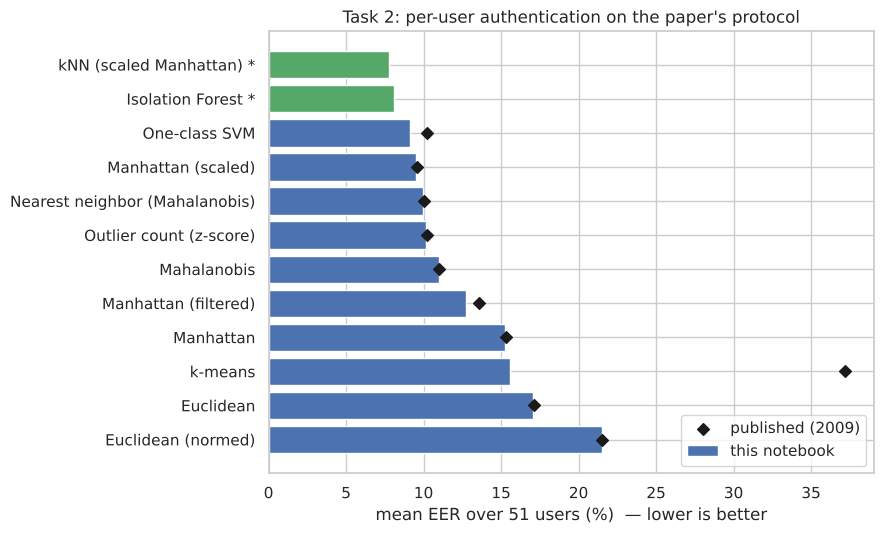

kNN (scaled Manhattan) vs Manhattan (scaled): 7.8% vs 9.5%, lower EER for 39/51 users (0 ties), Wilcoxon signed-rank p = 0.00021


Isolation Forest EER by seed: {42: np.float64(8.1), 0: np.float64(8.54), 1: np.float64(8.47), 2: np.float64(8.41)} -> 8.4 ± 0.2%


In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
order = main.detector.tolist()[::-1]
y = np.arange(len(order))
ax.barh(y, 100 * main.eer.values[::-1], color=["C2" if o.endswith("*") else "C0" for o in order], label="this notebook")
ax.scatter(100 * main.published.values[::-1], y, color="k", marker="D", zorder=3, label="published (2009)")
ax.set_yticks(y); ax.set_yticklabels(order)
ax.set_xlabel("mean EER over 51 users (%)  — lower is better")
ax.set_title("Task 2: per-user authentication on the paper's protocol")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Is the best new detector significantly better than the paper's best? Paired over the same 51 users.
best_new = min(NEW, key=lambda n: EERS[n].mean())
stat, pval = wilcoxon(EERS[best_new], EERS["Manhattan (scaled)"])
wins = int((EERS[best_new] < EERS["Manhattan (scaled)"]).sum()); ties = int((EERS[best_new] == EERS["Manhattan (scaled)"]).sum())
print(f"{best_new} vs Manhattan (scaled): {100*EERS[best_new].mean():.1f}% vs {100*EERS['Manhattan (scaled)'].mean():.1f}%, "
      f"lower EER for {wins}/51 users ({ties} ties), Wilcoxon signed-rank p = {pval:.2g}")

# Isolation Forest is random; kNN and the paper's detectors are deterministic. How much does the seed move it?
_mf = _parse("Isolation Forest", float)
if_seeds = {s: evaluate(make_iforest(max_features=_mf, seed=s), TEST)[0].mean() for s in (SEED, 0, 1, 2)}
print("Isolation Forest EER by seed:", {s: round(100 * v, 2) for s, v in if_seeds.items()},
      f"-> {100*np.mean(list(if_seeds.values())):.1f} ± {100*np.std(list(if_seeds.values())):.1f}%")

**Reading the results**

- **The replication works.** 7 of the paper's 10 detectors match the published mean EER to within 0.1 points: Euclidean, Euclidean (normed), Manhattan, Manhattan (scaled), Mahalanobis, nearest neighbor (Mahalanobis) and outlier count. The per-user std matches too. So the protocol, the impostor sampling and the EER computation all match the paper's.
- **The three that differ:**
  - **One-class SVM** (9.1% vs 10.2%): γ = 0.1 was chosen on validation. With sklearn's default γ ("scale") it gives 10.2%, the published value.
  - **Manhattan (filtered)** (12.8% vs 13.6%): the paper does not say exactly how the outlier filter is computed.
  - **k-means** (15.6% vs 37.2%): ours uses 10 random restarts. The paper's number is far worse, and the paper does not give enough detail to reproduce it.
- **The best detector is new.** kNN with scaled-Manhattan distance and k = 1 (chosen on validation) reaches **7.8%**. That beats the paper's best, Manhattan (scaled) at 9.5%, for 39 of 51 users (Wilcoxon signed-rank p = 0.0002). It also has the smallest spread across users (std 5.2).
- **Isolation Forest** reaches 8.1% at seed 42, but **8.4 ± 0.2%** across four seeds (see the printout above). Report it as about 8.4%. kNN is deterministic, so its 7.8% is exact.
- **Why kNN helps (interpretation, tested in sections 7-8):** a user's 200 training reps span four sessions while their typing speeds up. A mean template sits between their old and new typing. A nearest-neighbour match can use whichever past rep is closest, which for a drifting user is usually a recent one.
- **Zero-miss FAR** is the share of genuine attempts rejected when the threshold is strict enough to block every impostor. It is 35% for kNN and 60% for Manhattan (scaled). No detector is close to usable as the only login factor, so keystroke dynamics fits as a second factor or a continuous background check.

## 5. ROC curves and the error trade-off
The EER is one point on each user's ROC curve. To show whole curves, each user's curve is interpolated onto a common false-accept grid and the 51 curves are averaged. The dashed diagonal marks FAR = FRR, so each curve crosses it near its EER.

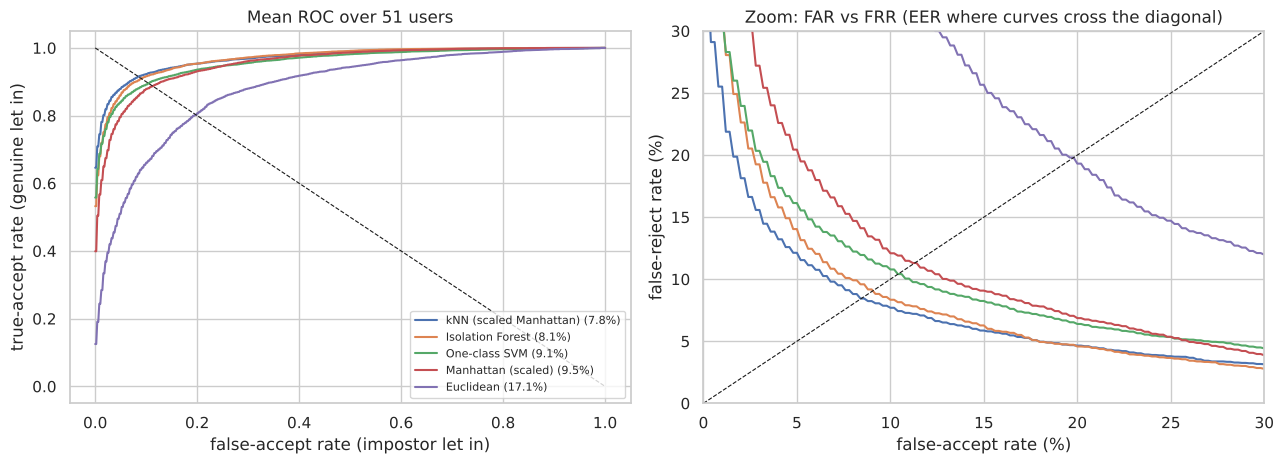

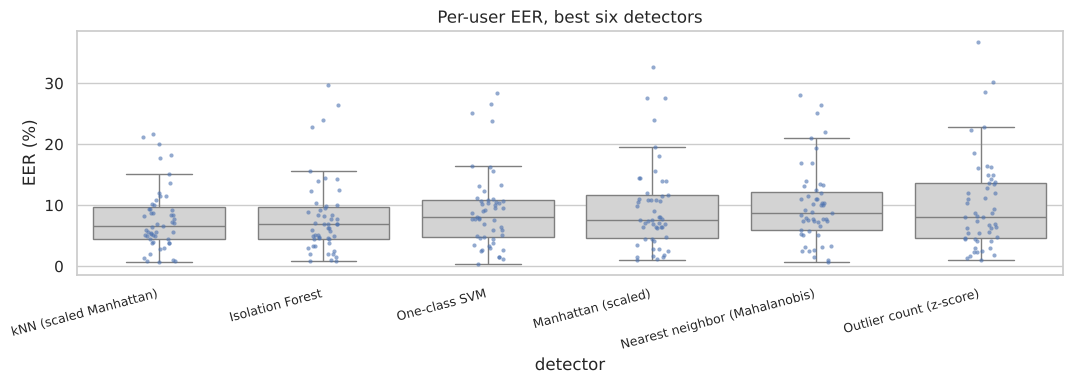

In [9]:
grid_far = np.linspace(0, 1, 501)
def mean_roc(scores):
    frrs = []
    for s in scores:
        y = np.r_[np.ones(len(s["gen"])), np.zeros(len(s["imp"]))]
        fpr, tpr, _ = roc_curve(y, np.r_[s["gen"], s["imp"]])
        frrs.append(1 - np.interp(grid_far, fpr, tpr))
    return np.mean(frrs, 0)

show_dets = [main.detector.iloc[i].rstrip(" *") for i in range(4)] + ["Euclidean"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for n in show_dets:
    frr = mean_roc(SCORES[n])
    axes[0].plot(grid_far, 1 - frr, label=f"{n} ({100*EERS[n].mean():.1f}%)")
    axes[1].plot(100 * grid_far, 100 * frr, label=n)
axes[0].plot([0, 1], [1, 0], "k--", lw=0.8)
axes[0].set_xlabel("false-accept rate (impostor let in)"); axes[0].set_ylabel("true-accept rate (genuine let in)")
axes[0].set_title("Mean ROC over 51 users"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].plot([0, 50], [0, 50], "k--", lw=0.8)
axes[1].set_xlim(0, 30); axes[1].set_ylim(0, 30)
axes[1].set_xlabel("false-accept rate (%)"); axes[1].set_ylabel("false-reject rate (%)")
axes[1].set_title("Zoom: FAR vs FRR (EER where curves cross the diagonal)")
plt.tight_layout(); plt.show()

# Spread across users: a mean EER of ~9% hides users near 0% and users above 25%.
top = [main.detector.iloc[i].rstrip(" *") for i in range(6)]
long = pd.DataFrame({n: 100 * EERS[n] for n in top}).melt(var_name="detector", value_name="EER (%)")
plt.figure(figsize=(11, 4))
sns.boxplot(data=long, x="detector", y="EER (%)", color="lightgray", showfliers=False)
sns.stripplot(data=long, x="detector", y="EER (%)", size=3, alpha=0.6)
plt.xticks(rotation=15, ha="right", fontsize=9); plt.title("Per-user EER, best six detectors"); plt.tight_layout(); plt.show()

## 6. Practiced impostors
The paper's impostors are each other user's **first** five attempts (session 1), when they are still learning the password. A real attacker might have practised. Here the **same detectors** (same training data, same genuine test reps) are scored against impostors taken from the first five reps of **session 5**, after each impostor has typed the password 200 times.

,detector,paper impostors (session 1),practiced impostors (session 5),increase
0,kNN (scaled Manhattan),7.8,12.3,4.5
1,Isolation Forest,8.1,13.9,5.8
2,One-class SVM,9.1,13.8,4.6
3,Manhattan (scaled),9.5,14.6,5.0
4,Nearest neighbor (Mahalanobis),10.0,14.9,5.0
5,Outlier count (z-score),10.1,16.1,6.0
6,Mahalanobis,11.0,15.4,4.4
7,Manhattan (filtered),12.8,19.6,6.9
8,Manhattan,15.3,22.3,7.0
9,k-means,15.6,21.4,5.8


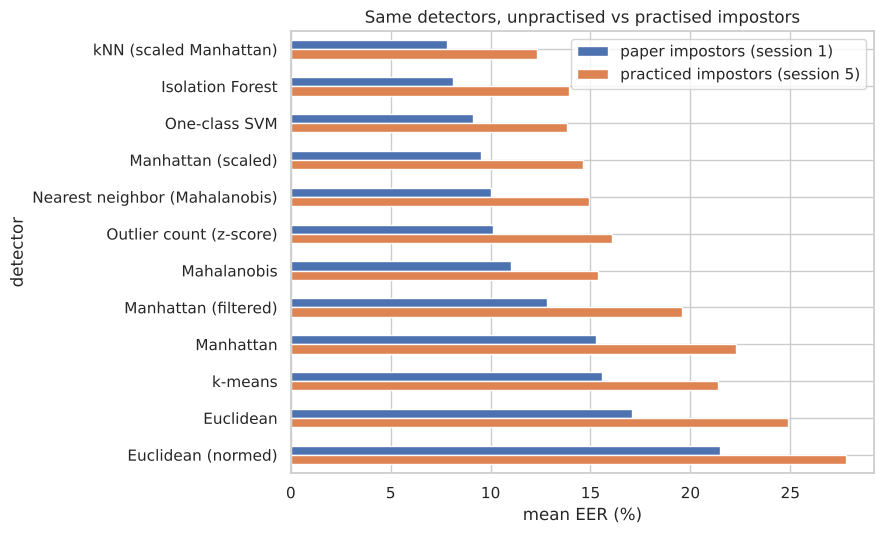

In [10]:
prac = pd.DataFrame({"detector": list(DETECTORS),
                     "paper impostors (session 1)": [100 * EERS[n].mean() for n in DETECTORS],
                     "practiced impostors (session 5)": [100 * EERS_PRACTICED[n].mean() for n in DETECTORS]})
prac["increase"] = prac.iloc[:, 2] - prac.iloc[:, 1]
prac = prac.sort_values("paper impostors (session 1)").round(1).reset_index(drop=True)
display(prac)
for n in DETECTORS:
    append_result(n, TASK + "_practiced_impostors", "eer_mean", EERS_PRACTICED[n].mean(), path=RESULTS_PATH)

ax = prac.set_index("detector")[["paper impostors (session 1)", "practiced impostors (session 5)"]].plot.barh(figsize=(9, 5.5))
ax.invert_yaxis(); ax.set_xlabel("mean EER (%)"); ax.set_title("Same detectors, unpractised vs practised impostors")
plt.tight_layout(); plt.show()

**Reading this:** every detector loses 4.4-7.8 EER points against impostors who have practised the password, and the ranking barely changes. kNN is still best at 12.3%. So the paper's headline numbers, ours included, are optimistic for an attacker who rehearses the victim's password. The report should state which impostor protocol a number uses. This also explains the gap found in the Task 2 sample code in A's handoff, which drew impostors from session 5.

## 7. Drift across the test sessions
Users get faster over time (Task 1 found typing time drops by 23-27% from session 1 to sessions 5-8). Each detector was trained on sessions 1-4. Here the genuine test reps are split by session (50 per session) and scored against the same 250 impostors. If templates age, EER should rise from session 5 to session 8. (Person C covers drift for the deep models; these are the classical numbers for comparison.)

session,5,6,7,8,s8 - s5
detector,,,,,
kNN (scaled Manhattan),6.9,7.1,7.7,7.9,1.0
Isolation Forest,6.7,7.2,7.9,9.1,2.4
One-class SVM,8.0,8.0,9.3,10.1,2.1
Manhattan (scaled),8.0,8.2,9.8,10.0,2.0
Nearest neighbor (Mahalanobis),8.8,8.6,9.8,10.9,2.1
Outlier count (z-score),8.8,9.2,9.9,10.5,1.7
Mahalanobis,9.9,9.5,11.3,11.9,2.0
Manhattan (filtered),11.9,11.7,12.6,13.1,1.2
Manhattan,13.8,13.9,15.3,16.0,2.2


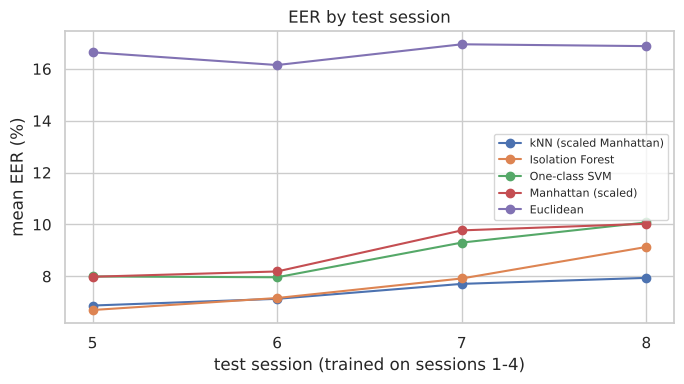

In [11]:
drift_rows = []
for n in DETECTORS:
    for s in CFG["TEST_SESSIONS"]:
        e = np.mean([eer(sc["gen"][p["ge_sess"] == s], sc["imp"]) for sc, p in zip(SCORES[n], TEST)])
        drift_rows.append((n, s, e))
        append_result(n, TASK + "_by_session", f"eer_session{s}", e, path=RESULTS_PATH)
drift = pd.DataFrame(drift_rows, columns=["detector", "session", "eer"])
drift_tab = (100 * drift.pivot(index="detector", columns="session", values="eer")).round(1)
drift_tab["s8 - s5"] = drift_tab[8] - drift_tab[5]
display(drift_tab.loc[main.detector.str.rstrip(" *")])

plt.figure(figsize=(7, 4))
for n in show_dets:
    d = drift[drift.detector == n]
    plt.plot(d.session, 100 * d.eer, "o-", label=n)
plt.xticks(CFG["TEST_SESSIONS"]); plt.xlabel("test session (trained on sessions 1-4)"); plt.ylabel("mean EER (%)")
plt.title("EER by test session"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading this:** for the good detectors, EER rises steadily from session 5 to session 8: by about 2 points for Manhattan (scaled), one-class SVM and nearest neighbor (Mahalanobis), and 2.4 for Isolation Forest. A template enrolled on sessions 1-4 ages as the user keeps changing. kNN degrades least (+1.0), which fits the explanation in section 4. Euclidean and k-means barely change, but only because they are poor in every session. This is the classical counterpart to Task 1's drop from 89.6% to 79.8% identification accuracy, and to Person C's drift analysis.

## 8. Ablations
**8a. Which features matter?** All 31 features, the 21 independent ones (H + UD, since DD = H + UD), hold times only (11), and down-down only (10).

**8b. How much enrolment typing is needed, and which part?** Each detector is trained on n of the user's 200 training reps. Two ways to pick them: the **first n** (oldest) or the **last n** (most recent, closest in time to the test sessions). Same test set throughout.

In [12]:
ABL = ["Manhattan (scaled)", "Nearest neighbor (Mahalanobis)", "Outlier count (z-score)", "One-class SVM", "Isolation Forest", "kNN (scaled Manhattan)"]
feature_sets = {"all 31": None, "H + UD (21)": H_idx + UD_idx, "H only (11)": H_idx, "DD only (10)": DD_idx}
fa = pd.DataFrame({fs: [100 * evaluate(DETECTORS[n], TEST, cols=cols)[0].mean() for n in ABL]
                   for fs, cols in feature_sets.items()}, index=ABL).round(1)
print("8a. Mean EER (%) by feature set")
display(fa)

8a. Mean EER (%) by feature set


,all 31,H + UD (21),H only (11),DD only (10)
Manhattan (scaled),9.5,9.4,15.3,15.0
Nearest neighbor (Mahalanobis),10.0,10.0,16.8,12.1
Outlier count (z-score),10.1,10.4,17.5,17.7
One-class SVM,9.1,9.7,15.4,14.6
Isolation Forest,8.1,7.6,15.3,12.3
kNN (scaled Manhattan),7.8,7.6,16.0,11.3


8b. Mean EER (%) by number of training reps


train_reps                                            25    50    100   200
detector                       which                                       
Isolation Forest               first n (oldest)      15.1  12.1   9.8   8.1
                               last n (most recent)   6.6   6.5   6.8   8.1
Manhattan (scaled)             first n (oldest)      18.9  15.4  12.3   9.5
                               last n (most recent)   7.8   7.8   8.3   9.5
Nearest neighbor (Mahalanobis) first n (oldest)      25.6  16.6  13.0  10.0
                               last n (most recent)  14.1  10.4   9.2  10.0
One-class SVM                  first n (oldest)      17.4  15.1  11.7   9.1
                               last n (most recent)   9.5   8.8   8.4   9.1
Outlier count (z-score)        first n (oldest)      18.2  15.1  12.0  10.1
                               last n (most recent)   6.4   7.0   7.8  10.1
kNN (scaled Manhattan)         first n (oldest)      15.2  12.8   9.9   7.8
                               last n (most recent)   7.6   7.3   7.1   7.8

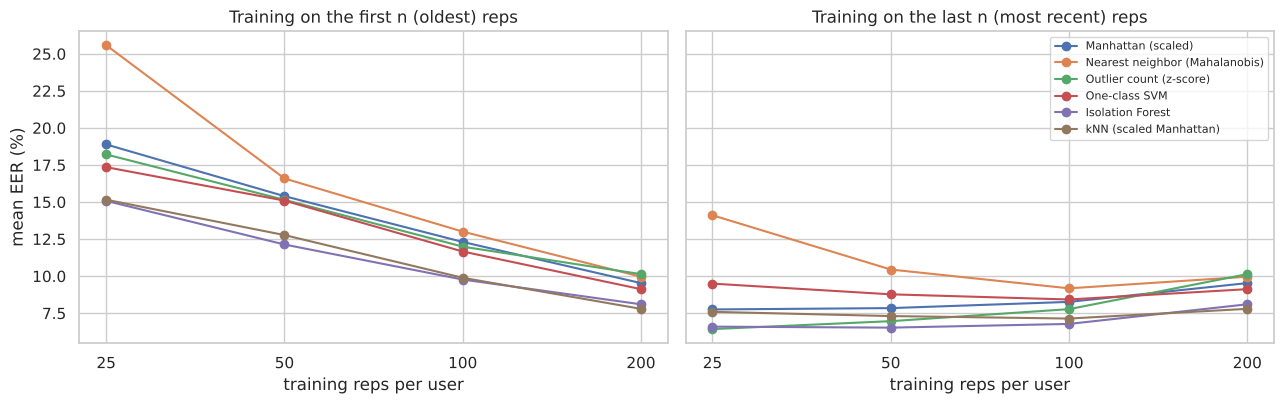

In [13]:
size_rows = []
for n_reps in (25, 50, 100, 200):
    for which, sl in (("first n (oldest)", slice(0, n_reps)), ("last n (most recent)", slice(200 - n_reps, 200))):
        for n in ABL:
            size_rows.append((n, n_reps, which, evaluate(DETECTORS[n], TEST, train_slice=sl)[0].mean()))
size = pd.DataFrame(size_rows, columns=["detector", "train_reps", "which", "eer"])
print("8b. Mean EER (%) by number of training reps")
display((100 * size.pivot_table(index=["detector", "which"], columns="train_reps", values="eer")).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, which in zip(axes, ("first n (oldest)", "last n (most recent)")):
    for n in ABL:
        d = size[(size.detector == n) & (size.which == which)]
        ax.plot(d.train_reps, 100 * d.eer, "o-", label=n)
    ax.set_xscale("log"); ax.set_xticks([25, 50, 100, 200]); ax.set_xticklabels([25, 50, 100, 200])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("training reps per user"); ax.set_title(f"Training on the {which} reps")
axes[0].set_ylabel("mean EER (%)"); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**8c. Does the recency effect survive without the test set?** 8b looked at test EERs, so it cannot be used to *choose* a training window. Repeat the comparison on the validation protocol (train on sessions 1-3, genuine = session 4): all 150 reps vs the oldest 50 (session 1) vs the most recent 50 (session 3).

In [14]:
rec = pd.DataFrame({label: [100 * evaluate(DETECTORS[n], VAL, train_slice=sl)[0].mean() for n in ABL]
                    for label, sl in (("all 150", slice(0, 150)), ("oldest 50 (session 1)", slice(0, 50)),
                                      ("most recent 50 (session 3)", slice(100, 150)))}, index=ABL).round(1)
print("8c. Validation EER (%) by training window")
display(rec)

8c. Validation EER (%) by training window


,all 150,oldest 50 (session 1),most recent 50 (session 3)
Manhattan (scaled),10.8,16.1,10.0
Nearest neighbor (Mahalanobis),12.8,18.8,12.1
Outlier count (z-score),12.4,16.3,9.6
One-class SVM,11.3,16.6,11.0
Isolation Forest,10.3,14.5,10.4
kNN (scaled Manhattan),10.2,14.1,10.2


**Reading the ablations**

- **Features (8a):** the 21 independent features (H + UD) do as well as all 31, and slightly better for Isolation Forest and kNN (7.6%). The 10 DD columns add no information, since DD = H + UD. Hold times alone and down-down times alone are both far worse (11-18%). Holds and transitions carry complementary information, and the combination is what identifies a typist.
- **Training size (8b), oldest reps first:** more data helps steadily, from about 15-26% EER with 25 reps to 8-10% with 200.
- **Training size (8b), most recent reps first:** 25-50 recent reps already match or beat all 200 for every detector except nearest neighbor (Mahalanobis), which needs more than 31 reps to estimate a covariance. Outlier count goes from 10.1% (all 200) to 6.4% (last 25), and Manhattan (scaled) from 9.5% to 7.8%.
- **Validation check (8c):** without touching test, the most recent 50 reps are within 0.1 points of all 150, or better, for every detector (Isolation Forest 10.4% vs 10.3%; outlier count 9.6% vs 12.4%). The oldest 50 are clearly worse (14-19% vs 10-12%). The effect is smaller than on test because session 3 is only one session before session 4, while sessions 5-8 are up to four sessions away from the enrolment data.
- **Conclusion:** for this data, how recent the enrolment typing is matters more than how much of it there is. A deployed system should keep updating each user's template with recent successful logins (adaptive templates). This is a recommendation for future work. Every result in this notebook still uses the paper's fixed 200-rep enrolment so they remain comparable with the published table.

## 9. Per-user difficulty
Which users are hardest to protect, and is that consistent across detectors? Task 1's hardest users to *identify* (lowest recall with the 1D-CNN) were 37, 54, 32, 16, 2, 21, 31 and 47. Being hard to identify and being easy to impersonate are related but not the same question.

In [15]:
best3 = [main.detector.iloc[i].rstrip(" *") for i in range(3)]
pu = pd.DataFrame({n: EERS[n] for n in DETECTORS}, index=users)
pu["mean_best3"] = pu[best3].mean(1)
hard = pu.sort_values("mean_best3", ascending=False)
print("Hardest users to authenticate (EER %, best three detectors):")
display((100 * hard[best3 + ["mean_best3"]].head(8)).round(1))
print("Easiest:", ", ".join(f"{u} ({100*v:.1f}%)" for u, v in hard.mean_best3.tail(5)[::-1].items()))
print("Users with EER = 0 for", best3[0], ":", int((pu[best3[0]] == 0).sum()), "of 51")

TASK1_HARDEST = [37, 54, 32, 16, 2, 21, 31, 47]   # from task1_identification.ipynb, section 7
overlap = set(hard.index[:8]) & set(TASK1_HARDEST)
print("Overlap with Task 1's 8 hardest-to-identify users:", sorted(overlap) or "none")

rank_corr = pu[list(DETECTORS)].rank().corr(method="spearman")
print(f"Mean Spearman correlation of per-user EER ranks across detectors: "
      f"{rank_corr.values[np.triu_indices(len(DETECTORS), 1)].mean():.2f}")

pu.drop(columns="mean_best3").rename_axis("subject").to_csv(os.path.join(ROOT, "results_task2_classical_per_user.csv"))

Hardest users to authenticate (EER %, best three detectors):


,kNN (scaled Manhattan),Isolation Forest,One-class SVM,mean_best3
47,20.1,29.8,25.1,25.0
32,21.1,22.9,28.4,24.1
2,21.7,24.0,26.6,24.1
31,18.3,26.5,23.8,22.8
40,17.8,14.5,15.6,16.0
16,15.2,15.6,13.1,14.6
3,12.0,12.4,16.4,13.6
34,10.9,12.4,16.2,13.2


Easiest: 36 (0.8%), 55 (1.2%), 52 (1.3%), 43 (1.4%), 53 (2.0%)
Users with EER = 0 for kNN (scaled Manhattan) : 0 of 51
Overlap with Task 1's 8 hardest-to-identify users: [2, 16, 31, 32, 47]
Mean Spearman correlation of per-user EER ranks across detectors: 0.80


**Reading this:** difficulty is concentrated in a few users. Users 47, 32, 2 and 31 average 23-25% EER over the best three detectors, while the easiest (36, 55, 52) are around 1%. The ranking of users is very similar across all 12 detectors (mean Spearman 0.80). So difficulty is mostly a property of the user, such as inconsistent typing, not of the detector. 5 of Task 1's 8 hardest-to-identify users (2, 16, 31, 32, 47) are also among the 8 hardest to authenticate, which links sections A and B of the report. Per-user EERs for every detector are saved to `results_task2_classical_per_user.csv`.

## 10. Summary and saved artifacts
For the Streamlit tab (weeks 11-12), save each user's enrolment data and a decision threshold for the best detector by **validation** EER. The threshold is the EER point on the validation protocol, so it is never fitted on test data.

In [16]:
import joblib

def eer_threshold(gen, imp):
    y = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
    fpr, tpr, thr = roc_curve(y, np.r_[gen, imp])
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return float(thr[i])

val_eer_all = {n: evaluate(f, VAL)[0].mean() for n, f in DETECTORS.items()}
demo_name = min(val_eer_all, key=val_eer_all.get)
fit = DETECTORS[demo_name]
thresholds = {}
for p in VAL:
    f = fit(p["tr"])
    thresholds[p["user"]] = eer_threshold(f(p["ge"]), f(p["im"]))
enrol = {p["user"]: p["tr"] for p in TEST}            # sessions 1-4, the same data the test results used

os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
out = os.path.join(ROOT, "models", "task2_best_classical.joblib")
joblib.dump({"name": demo_name, "feat_cols": feat_cols, "enrol": enrol, "thresholds": thresholds,
             "settings": chosen, "note": "score = detector fitted on enrol[user]; accept if score >= thresholds[user]"}, out)
print(f"best on validation: {demo_name} ({100*val_eer_all[demo_name]:.1f}% val EER, {100*EERS[demo_name].mean():.1f}% test EER)")
print("saved ->", out)

final = main[["detector", "eer", "eer_std", "published", "zero_miss_far"]].copy()
for c in ("eer", "eer_std", "published", "zero_miss_far"):
    final[c] = (100 * final[c]).round(1)
display(final)
print("results rows for this notebook:", pd.read_csv(RESULTS_PATH).task.str.startswith(TASK).sum())

best on validation: kNN (scaled Manhattan) (10.2% val EER, 7.8% test EER)
saved -> /home/claude/kd/models/task2_best_classical.joblib


,detector,eer,eer_std,published,zero_miss_far
0,kNN (scaled Manhattan) *,7.8,5.2,NaN,35.4
1,Isolation Forest *,8.1,6.3,NaN,46.8
2,One-class SVM,9.1,6.3,10.2,44.2
3,Manhattan (scaled),9.5,7.0,9.6,60.1
4,Nearest neighbor (Mahalanobis),10.0,6.3,10.0,46.8
5,Outlier count (z-score),10.1,7.7,10.2,78.2
6,Mahalanobis,11.0,6.4,11.0,48.2
7,Manhattan (filtered),12.8,8.0,13.6,69.7
8,Manhattan,15.3,9.2,15.3,84.3
9,k-means,15.6,7.3,37.2,69.7


results rows for this notebook: 96


**Task 2 (classical) in one paragraph:** the paper's evaluation is reproduced to within 0.1 EER points for 7 of its 10 detectors (best: Manhattan (scaled), 9.5% vs 9.6% published). A nearest-neighbour detector with scaled-Manhattan distance, chosen on validation only, reaches **7.8%** and beats the paper's best for 39 of 51 users (p = 0.0002). Three findings go beyond the paper:
1. Practised impostors raise every detector's EER by 4-8 points.
2. Templates age: EER rises from test session 5 to session 8.
3. Recent enrolment typing matters more than the amount of it, confirmed on validation.

**Saved:**
- `results.csv`: 96 rows. `task2_classical` holds `eer_mean`, `eer_std` and `zero_miss_far_mean` per detector; `task2_classical_practiced_impostors` and `task2_classical_by_session` hold the extra experiments.
- `results_task2_classical_per_user.csv`: per-user EER for every detector.
- `models/task2_best_classical.joblib`: the detector with the best validation EER, each user's sessions 1-4 enrolment reps, and per-user thresholds set at the validation EER point.

Use it in the Streamlit tab like this:
```python
art = joblib.load("models/task2_best_classical.joblib")      # name: kNN (scaled Manhattan), k = 1
tr = art["enrol"][claimed_user]; a = np.abs(tr - tr.mean(0)).mean(0)
score = -np.abs(x / a - tr / a).sum(1).min()                  # x = one typing sample, 31 features in art["feat_cols"] order
accept = score >= art["thresholds"][claimed_user]
```
The thresholds come from the validation protocol (enrolment on sessions 1-3), so they are slightly conservative for the sessions 1-4 enrolment. That is fine for a demo, and it keeps test data out of every choice.